
##### These are TCGA (The Cancer Genome Atlas) cancer abbreviations commonly used in bioinformatics, genomics, and machine learning datasets.

| Abbreviation | Full Form                         | Organ                      |
| ------------ | --------------------------------- | -------------------------- |
| **KIRC**     | Kidney Renal Clear Cell Carcinoma | 🩺 Kidney                  |
| **BRCA**     | Breast Invasive Carcinoma         | 🩺 Breast                  |
| **COAD**     | Colon Adenocarcinoma              | 🩺 Colon (Large Intestine) |
| **LUAD**     | Lung Adenocarcinoma               | 🩺 Lung                    |
| **PRAD**     | Prostate Adenocarcinoma           | 🩺 Prostate                |


KIRC → Most common type of kidney cancer.

BRCA → Breast cancer originating in breast tissue.

COAD → Colon cancer arising from glandular cells.

LUAD → Most common subtype of non-small cell lung cancer.

PRAD → Most common prostate cancer in men.


0 → KIRC (Kidney Cancer)

1 → BRCA (Breast Cancer)

2 → COAD (Colon Cancer)

3 → LUAD (Lung Cancer)

4 → PRAD (Prostate Cancer)

## Import Python libraries

## Read data

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.preprocessing import label_binarize

from sklearn.preprocessing import MinMaxScaler

from sklearn.feature_selection import mutual_info_classif

from sklearn.multiclass import OneVsRestClassifier

from sklearn.svm import SVC

from sklearn.metrics import balanced_accuracy_score,f1_score,precision_score, recall_score

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

from sklearn.metrics import roc_curve,auc
from sklearn.metrics import roc_auc_score


In [2]:

dataframe=pd.read_csv("cancer_gene_expression.csv")

dataframe

,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7,gene_8,gene_9,gene_10,...,gene_7992,gene_7993,gene_7994,gene_7995,gene_7996,gene_7997,gene_7998,gene_7999,gene_8000,Cancer_Type
0,0.0,0.000000,0.0,2.088413,0.0,0.0,0.0,0.0,0.550605,2.815760,...,11.558803,8.881802,6.014840,6.643534,11.740624,7.065012,9.932659,6.928584,2.088413,KIRC
1,0.0,0.000000,0.0,3.205955,0.0,0.0,0.0,0.0,0.425244,2.354396,...,11.062829,9.032864,5.054193,6.432320,12.104985,7.300746,9.872796,5.039231,2.448002,KIRC
2,0.0,0.000000,0.0,4.746646,0.0,0.0,0.0,0.0,2.639417,1.657091,...,12.497640,7.198160,0.943434,7.371690,11.202357,8.426588,11.176890,3.119738,4.433988,BRCA
3,0.0,0.000000,0.0,1.173191,0.0,0.0,0.0,0.0,1.527371,2.732899,...,11.261713,8.725676,6.300418,6.036451,11.732303,7.559469,9.596453,2.863046,3.380342,KIRC
4,0.0,0.000000,0.0,1.366532,0.0,0.0,0.0,0.0,0.000000,3.388355,...,12.241965,7.685204,5.142948,6.355788,11.493950,8.139444,10.189256,6.544487,0.839395,COAD
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
796,0.0,2.933384,0.0,1.683921,0.0,0.0,0.0,0.0,0.635336,1.252839,...,9.985842,9.469967,4.225275,6.955336,11.722206,7.309940,10.986119,6.396848,1.252839,BRCA
797,0.0,0.000000,0.0,2.772625,0.0,0.0,0.0,0.0,0.534759,3.761764,...,12.334681,8.157327,1.482797,6.758183,11.403838,9.005347,11.012045,5.386625,1.697640,COAD
798,0.0,0.408277,0.0,1.854754,0.0,0.0,0.0,0.0,0.000000,0.986520,...,11.671992,8.859616,6.393828,6.427115,11.596586,7.454127,10.718533,5.507417,1.398131,BRCA
799,0.0,0.639232,0.0,3.226971,0.0,0.0,0.0,0.0,1.921322,0.639232,...,12.237087,5.753976,4.192478,6.614875,11.183245,7.544261,10.649382,5.282158,0.639232,BRCA



## Data Exploration & Cleaning




In [3]:

print(dataframe.shape)

(801, 8001)


In [4]:

print(dataframe.columns[0:8000])

Index(['gene_1', 'gene_2', 'gene_3', 'gene_4', 'gene_5', 'gene_6', 'gene_7',
       'gene_8', 'gene_9', 'gene_10',
       ...
       'gene_7991', 'gene_7992', 'gene_7993', 'gene_7994', 'gene_7995',
       'gene_7996', 'gene_7997', 'gene_7998', 'gene_7999', 'gene_8000'],
      dtype='str', length=8000)


In [5]:
#lets check the name of the last column of this dataframe

In [6]:

dataframe.columns[-1]

'Cancer_Type'

In [7]:
#check for missing values

In [8]:

datanul=dataframe.isnull().sum()
datanul

gene_1         0
gene_2         0
gene_3         0
gene_4         0
gene_5         0
              ..
gene_7997      0
gene_7998      0
gene_7999      0
gene_8000      0
Cancer_Type    0
Length: 8001, dtype: int64

In [9]:

g=[i for i in datanul if i>0]

print('columns with missing values:%d'%len(g))

columns with missing values:0


https://chatgpt.com/share/6a05551c-417c-8323-82f9-eebd8445fa78

In [10]:

print(dataframe['Cancer_Type'].unique())

<ArrowStringArray>
['KIRC', 'BRCA', 'COAD', 'LUAD', 'PRAD']
Length: 5, dtype: str


In [11]:

print(dataframe['Cancer_Type'].value_counts())

Cancer_Type
BRCA    300
KIRC    146
LUAD    141
PRAD    136
COAD     78
Name: count, dtype: int64


We can see that there are 5 classes/cancer types. 

<Axes: xlabel='Cancer_Type'>

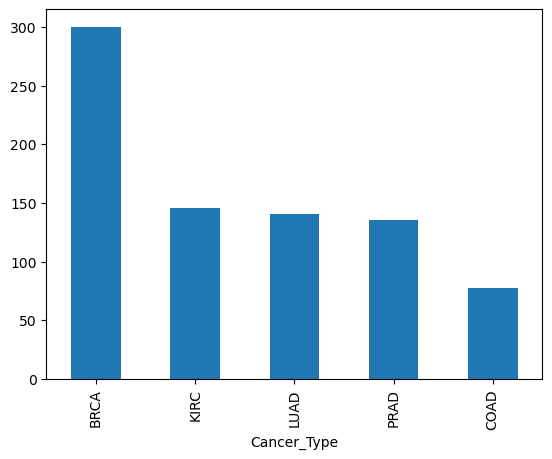

In [12]:

dataframe['Cancer_Type'].value_counts().plot.bar()

 ## **Data preprocesing** 

In [13]:

X=dataframe.iloc[:,0:-1]

y=dataframe.iloc[:,-1]

In [14]:
X.shape

(801, 8000)

In [15]:
y.shape

(801,)

\
**Encode labels**

In [16]:

label_encoder=LabelEncoder()

label_encoder.fit(y)
y_encoded=label_encoder.transform(y)

labels=label_encoder.classes_

classes=np.unique(y_encoded)

In [17]:
labels

array(['BRCA', 'COAD', 'KIRC', 'LUAD', 'PRAD'], dtype=object)

In [18]:
classes

array([0, 1, 2, 3, 4])

In [19]:

X_train,X_test,y_train,y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded  
)

In [20]:
dataframe.iloc[:,0:10].describe()

,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7,gene_8,gene_9,gene_10
count,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000
mean,0.026642,0.231049,0.010844,2.405459,0.005799,0.065640,0.022036,0.028394,0.703998,1.916364
std,0.136850,0.656692,0.153859,0.797236,0.052265,0.213557,0.148917,0.161606,0.779321,0.877010
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,1.898595,0.000000,0.000000,0.000000,0.000000,0.000000,1.357214
50%,0.000000,0.000000,0.000000,2.358284,0.000000,0.000000,0.000000,0.000000,0.518031,1.877862
75%,0.000000,0.000000,0.000000,2.929355,0.000000,0.000000,0.000000,0.000000,1.123931,2.486792
max,1.482332,6.575004,3.778061,4.746646,0.570754,1.866275,2.169925,2.375957,4.541670,4.932231


In [21]:
X_train

,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7,gene_8,gene_9,gene_10,...,gene_7991,gene_7992,gene_7993,gene_7994,gene_7995,gene_7996,gene_7997,gene_7998,gene_7999,gene_8000
376,0.0,0.000000,0.0,3.586020,0.0,0.000000,0.0,0.0,0.000000,1.429589,...,7.316119,11.575402,8.254726,7.005041,7.014523,11.624786,7.331374,10.190269,4.834003,5.192466
157,0.0,0.000000,0.0,2.559125,0.0,0.000000,0.0,0.0,0.918157,4.088735,...,5.990978,11.817671,9.680247,6.547377,6.410729,11.383440,7.483372,10.638083,5.493177,1.875466
582,0.0,0.000000,0.0,3.336583,0.0,0.000000,0.0,0.0,0.000000,1.754674,...,6.675703,11.759776,8.928874,5.209952,6.845176,11.848482,7.531545,10.117215,5.989314,1.574683
772,0.0,0.000000,0.0,3.334239,0.0,1.094709,0.0,0.0,1.434882,1.434882,...,6.510943,11.443570,6.400458,3.870720,7.367292,11.098276,7.682496,10.131793,9.144709,3.334239
448,0.0,0.000000,0.0,3.067897,0.0,0.577634,0.0,0.0,0.000000,2.887681,...,6.195147,11.837545,8.993267,5.532875,6.469912,11.917577,7.980711,10.775075,7.122631,3.886189
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
406,0.0,0.000000,0.0,1.536749,0.0,0.000000,0.0,0.0,2.638954,2.936365,...,6.154929,11.500234,9.118225,7.982600,6.816408,11.400767,7.665478,10.030391,4.018892,0.963992
104,0.0,0.000000,0.0,2.756831,0.0,1.378401,0.0,0.0,0.000000,1.545820,...,8.756333,11.751611,7.214300,5.058104,6.124942,11.185873,8.698142,10.049903,3.570269,5.465762
709,0.0,1.287945,0.0,1.547154,0.0,0.566182,0.0,0.0,0.000000,2.276437,...,6.262033,11.289154,9.048909,4.371865,6.782605,11.557856,7.914672,10.969099,8.331087,1.547154
342,0.0,0.000000,0.0,2.431543,0.0,0.000000,0.0,0.0,1.301529,1.301529,...,8.348458,11.421492,7.999386,7.061485,7.065432,11.616668,7.737477,10.092242,7.395440,3.395310


In [22]:
y_train

array([0, 3, 2, 0, 1, 3, 4, 4, 2, 2, 4, 4, 0, 4, 0, 2, 4, 0, 4, 2, 3, 3,
       3, 1, 4, 0, 4, 3, 4, 1, 0, 0, 3, 4, 1, 0, 0, 4, 2, 2, 0, 0, 4, 1,
       0, 4, 1, 0, 1, 2, 0, 0, 0, 0, 4, 0, 0, 0, 4, 0, 0, 1, 0, 0, 0, 0,
       2, 0, 0, 1, 0, 0, 0, 0, 0, 0, 3, 0, 4, 3, 2, 0, 0, 4, 3, 4, 0, 4,
       0, 0, 3, 1, 4, 4, 3, 2, 0, 3, 2, 3, 0, 2, 4, 4, 3, 0, 0, 0, 0, 0,
       3, 2, 0, 4, 2, 0, 1, 2, 4, 1, 3, 0, 2, 2, 4, 1, 0, 0, 1, 3, 4, 2,
       4, 2, 1, 4, 4, 1, 0, 0, 0, 2, 3, 4, 0, 0, 2, 0, 1, 0, 1, 3, 2, 1,
       3, 0, 3, 2, 4, 0, 0, 3, 1, 2, 4, 0, 3, 2, 0, 4, 1, 2, 3, 0, 0, 3,
       4, 0, 3, 2, 2, 3, 0, 4, 1, 0, 0, 0, 2, 0, 3, 0, 2, 3, 0, 2, 0, 3,
       0, 4, 2, 2, 4, 0, 4, 0, 0, 0, 0, 2, 0, 2, 3, 0, 0, 0, 0, 3, 0, 0,
       4, 2, 0, 4, 4, 3, 3, 3, 4, 2, 1, 4, 0, 4, 1, 0, 0, 3, 2, 1, 3, 2,
       2, 2, 4, 3, 4, 0, 0, 0, 1, 2, 2, 1, 0, 0, 4, 3, 1, 0, 0, 0, 2, 3,
       0, 0, 0, 4, 4, 0, 3, 2, 0, 0, 0, 0, 0, 0, 0, 2, 0, 4, 1, 0, 2, 2,
       4, 4, 3, 0, 0, 4, 0, 2, 1, 0, 3, 2, 0, 2, 0,


### Data Normalization


In [23]:
# scale data between 0 and 1

min_max_scaler=MinMaxScaler()

X_train_norm = min_max_scaler.fit_transform(X_train)
X_test_norm = min_max_scaler.transform(X_test)

In [24]:
X_train_norm

array([[0.        , 0.        , 0.        , ..., 0.32040233, 0.38123883,
        0.53319143],
       [0.        , 0.        , 0.        , ..., 0.42750802, 0.44450024,
        0.19258327],
       [0.        , 0.        , 0.        , ..., 0.30292951, 0.49211495,
        0.16169722],
       ...,
       [0.        , 0.19588507, 0.        , ..., 0.5066786 , 0.71685688,
        0.15887037],
       [0.        , 0.        , 0.        , ..., 0.29695667, 0.62706203,
        0.34864934],
       [0.        , 0.21747676, 0.        , ..., 0.21208819, 0.1951522 ,
        0.07665322]], shape=(640, 8000))

### Feature Selection using Mutual Information

In [25]:

MI=mutual_info_classif(X_train_norm,y_train)

In [26]:

MI

array([0.        , 0.07500007, 0.        , ..., 0.142462  , 0.100691  ,
       0.08177227], shape=(8000,))

In [27]:
# select top n features. lets say 250.

n_features=250

selected_scores_indices=np.argsort(MI)[::-1][0:n_features]


### dear students you work with 500, 1000, 2500 also

In [28]:
selected_scores_indices

array([7952, 7740, 6130, 7953, 7177, 6876, 7564, 6796, 7975, 6914, 7412,
       6987, 6160, 7194, 7534, 7853, 7870, 7678, 7685, 6775, 7940, 7549,
       7618, 7597, 7369, 7849, 7897, 7711, 7943, 6848, 7845, 7763, 6705,
       6683, 7772, 6124, 7242, 7329, 7272, 6910, 7838, 6523, 7930, 7593,
       7633, 7054, 7155, 7458, 7386, 6342, 5602, 7650, 4778, 5689, 6739,
       7047, 7907, 7403, 7235, 7035, 7052, 6921, 5776, 7342, 7181, 7482,
       6764, 7963, 6614, 5852, 7914, 7895, 7690, 6890, 6303, 5191, 6507,
       6226, 7444, 5629, 6315, 7108, 6982, 7635, 7863, 7364, 7848, 6377,
       7725, 5626, 6559, 7532, 7964, 7658, 7821, 7154, 6502, 7890, 6772,
       7664, 6304, 7481, 6497, 7759, 7684, 2083, 6300, 4934, 7839, 7820,
       5765, 7753, 7344, 6562, 7467, 7951, 7502, 7620, 7787, 7328, 4868,
       7220, 6956, 4330, 7595, 7055, 6395, 6988, 7755, 6762, 7756, 6578,
       5914, 7982, 6116, 6142, 7330, 7698, 7988, 6363, 5892, 6845, 7872,
       6193, 7211, 6035, 7916, 7613, 7140, 6823, 57

In [29]:

X_train_selected=X_train_norm[:,selected_scores_indices]

X_test_selected=X_test_norm[:,selected_scores_indices]


In [30]:

X_train_selected.shape

(640, 250)

In [31]:
X_test_selected.shape

(161, 250)

## Classification

### Model Training

In [32]:
SVM = OneVsRestClassifier(
    SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale',
        probability=True,
        class_weight='balanced',
        random_state=42
    )
)

SVM

,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",SVC(class_wei...ndom_state=42)
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes`one-vs-rest problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: 0.20 `n_jobs` default changed from 1 to None",None
,"verbose verbose: int, default=0The verbosity level, if non zero, progress messages are printed.Below 50, the output is sent to stderr. Otherwise, the output is sentto stdout. The frequency of the messages increases with the verbositylevel, reporting all iterations at 10. See :class:`joblib.Parallel` formore details... versionadded:: 1.1",0
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001


In [33]:
SVM.fit(X_train_selected, y_train)


,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",SVC(class_wei...ndom_state=42)
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes`one-vs-rest problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: 0.20 `n_jobs` default changed from 1 to None",None
,"verbose verbose: int, default=0The verbosity level, if non zero, progress messages are printed.Below 50, the output is sent to stderr. Otherwise, the output is sentto stdout. The frequency of the messages increases with the verbositylevel, reporting all iterations at 10. See :class:`joblib.Parallel` formore details... versionadded:: 1.1",0
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001


In [34]:
y_pred = SVM.predict(X_test_selected)

y_pred[:30]

array([2, 0, 0, 4, 2, 2, 2, 0, 0, 3, 0, 0, 3, 0, 0, 1, 0, 2, 0, 3, 2, 3,
       0, 2, 0, 4, 0, 0, 2, 0])

In [35]:
pred_prob = SVM.predict_proba(X_test_selected)

pred_prob[:30]

array([[3.48316284e-04, 4.98930819e-03, 9.76662275e-01, 1.27863175e-02,
        5.21378302e-03],
       [9.91564404e-01, 5.89620204e-04, 1.05516336e-04, 3.89944811e-05,
        7.70146471e-03],
       [9.72553539e-01, 3.57408179e-03, 1.59770547e-03, 6.73974507e-03,
        1.55349291e-02],
       [2.22133010e-04, 1.36122208e-03, 1.34513279e-03, 1.02484960e-04,
        9.96969027e-01],
       [2.73877834e-03, 4.40661957e-04, 9.86439449e-01, 4.70735483e-04,
        9.91037531e-03],
       [1.60984623e-03, 1.47428108e-03, 9.93356834e-01, 9.96109353e-06,
        3.54907776e-03],
       [1.19973988e-02, 1.77278306e-02, 9.66707903e-01, 4.51833425e-04,
        3.11503451e-03],
       [9.60251434e-01, 2.49624457e-03, 4.39137769e-04, 2.84532475e-04,
        3.65286508e-02],
       [9.34385942e-01, 9.57134731e-03, 9.81808037e-04, 5.40185880e-02,
        1.04231435e-03],
       [1.65279206e-01, 2.00906914e-01, 3.99157654e-03, 6.26211281e-01,
        3.61102198e-03],
       [9.96384063e-01, 1.2335

In [36]:

y_pred[:30]

array([2, 0, 0, 4, 2, 2, 2, 0, 0, 3, 0, 0, 3, 0, 0, 1, 0, 2, 0, 3, 2, 3,
       0, 2, 0, 4, 0, 0, 2, 0])

In [37]:

balanced_acc = np.round(balanced_accuracy_score(y_test, y_pred), 4)
print('balanced_accuracy: %0.4f' % balanced_acc)

precision=np.round(precision_score(y_test,y_pred,average = 'weighted'),4)
print('precision:%0.4f'%precision)

recall=np.round(recall_score(y_test,y_pred,average = 'weighted'),4)
print('recall:%0.4f'%recall)

f1score=np.round(f1_score(y_test,y_pred,average = 'weighted'),4)
print('f1score:%0.4f'%f1score)


report=classification_report(y_test,y_pred, target_names=labels)
print('\n')
print('classification report\n\n')
print(report)

balanced_accuracy: 0.9742
precision:0.9820
recall:0.9814
f1score:0.9812


classification report


              precision    recall  f1-score   support

        BRCA       0.97      1.00      0.98        60
        COAD       1.00      0.94      0.97        16
        KIRC       1.00      0.93      0.97        30
        LUAD       0.97      1.00      0.98        28
        PRAD       1.00      1.00      1.00        27

    accuracy                           0.98       161
   macro avg       0.99      0.97      0.98       161
weighted avg       0.98      0.98      0.98       161



In [38]:
cm=confusion_matrix(y_test,y_pred)

In [39]:

cm

array([[60,  0,  0,  0,  0],
       [ 0, 15,  0,  1,  0],
       [ 2,  0, 28,  0,  0],
       [ 0,  0,  0, 28,  0],
       [ 0,  0,  0,  0, 27]])

In [40]:

cm_df=pd.DataFrame(cm,index=labels,columns=labels)
cm_df

,BRCA,COAD,KIRC,LUAD,PRAD
BRCA,60,0,0,0,0
COAD,0,15,0,1,0
KIRC,2,0,28,0,0
LUAD,0,0,0,28,0
PRAD,0,0,0,0,27


In [41]:

y_test_binarized=label_binarize(y_test,classes=classes)

print(y_test_binarized)


[[0 0 1 0 0]
 [1 0 0 0 0]
 [1 0 0 0 0]
 [0 0 0 0 1]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [1 0 0 0 0]
 [1 0 0 0 0]
 [0 0 0 1 0]
 [1 0 0 0 0]
 [1 0 0 0 0]
 [0 0 0 1 0]
 [1 0 0 0 0]
 [1 0 0 0 0]
 [0 1 0 0 0]
 [1 0 0 0 0]
 [0 0 1 0 0]
 [1 0 0 0 0]
 [0 0 0 1 0]
 [0 0 1 0 0]
 [0 0 0 1 0]
 [1 0 0 0 0]
 [0 0 1 0 0]
 [1 0 0 0 0]
 [0 0 0 0 1]
 [1 0 0 0 0]
 [1 0 0 0 0]
 [0 0 1 0 0]
 [1 0 0 0 0]
 [0 1 0 0 0]
 [0 0 0 1 0]
 [0 0 1 0 0]
 [1 0 0 0 0]
 [0 0 1 0 0]
 [1 0 0 0 0]
 [0 1 0 0 0]
 [0 0 0 0 1]
 [0 0 0 1 0]
 [0 0 0 1 0]
 [0 0 0 1 0]
 [0 0 0 0 1]
 [1 0 0 0 0]
 [1 0 0 0 0]
 [0 0 0 1 0]
 [1 0 0 0 0]
 [0 0 0 1 0]
 [0 0 1 0 0]
 [1 0 0 0 0]
 [0 0 0 1 0]
 [1 0 0 0 0]
 [1 0 0 0 0]
 [0 0 0 0 1]
 [1 0 0 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [1 0 0 0 0]
 [0 0 1 0 0]
 [0 0 0 0 1]
 [0 0 1 0 0]
 [0 1 0 0 0]
 [0 1 0 0 0]
 [1 0 0 0 0]
 [0 0 1 0 0]
 [0 1 0 0 0]
 [1 0 0 0 0]
 [0 0 0 0 1]
 [1 0 0 0 0]
 [1 0 0 0 0]
 [0 0 0 0 1]
 [1 0 0 0 0]
 [0 0 0 1 0]
 [0 0 1 0 0]
 [0 0 0 1 0]
 [0 0 1 0 0]
 [1 0 0 0 0]
 [0 0 1 0 0]

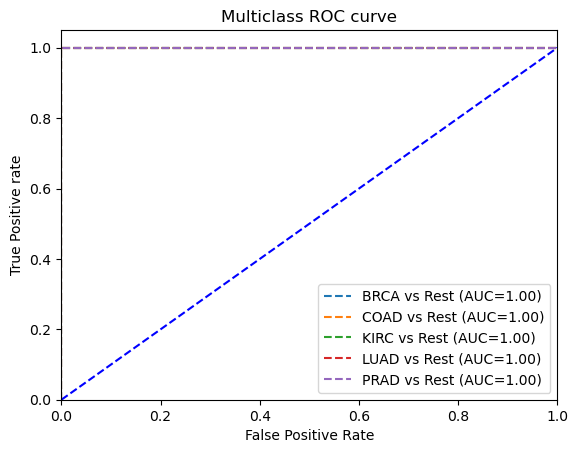

In [42]:

# roc curve for classes
fpr = {}
tpr = {}
thresh ={}
roc_auc = dict()

n_class = classes.shape[0]

for i in range(n_class):    
    fpr[i], tpr[i], thresh[i] = roc_curve(y_test_binarized[:,i], pred_prob[:,i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    
    # plotting    
    plt.plot(fpr[i], tpr[i], linestyle='--', 
             label='%s vs Rest (AUC=%0.2f)'%(labels[i],roc_auc[i]))

plt.plot([0,1],[0,1],'b--')
plt.xlim([0,1])
plt.ylim([0,1.05])
plt.title('Multiclass ROC curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive rate')
plt.legend(loc='lower right')
plt.show()    



<b>Mutual Information (MI)</b> quantifies how much knowing a feature reduces uncertainty about the class label.

    MI = 0 → feature is completely independent of the class (useless)
    
    MI > 0 → feature shares information with the class (useful)
    
    Higher MI → stronger relationship with the target
    

### Balanced accuracy

* Balanced Accuracy is a metric used to evaluate classification models, especially when your dataset is imbalanced.

* Instead of just measuring overall accuracy, balanced accuracy gives equal importance to each class.

<b>Balanced Accuracy </b> is used in both binary and multi-class classification.

It’s the arithmetic mean of sensitivity and specificity, its use case is when dealing with imbalanced data, i.e. when one of the target classes appears a lot more than the other.

Balanced Accuracy = (Sensitivity + Specificity) / 2


Why use Balanced Accuracy?

Standard accuracy can be misleading with imbalanced datasets.

Example: If 95% of samples are negative, predicting all negatives gives 95% accuracy but the model is useless.

Balanced Accuracy corrects this by equally considering performance on both classes.

### label_binarize() converts categorical class labels into a binary (0/1) matrix.

👉 It is mainly used for:

    Multi-class ROC-AUC

    One-vs-Rest (OvR) evaluation

    Probability-based metrics


In binary classification:

    y = [0, 1, 0, 1]

But in multi-class:

    y = [0, 2, 1, 2]



👉 Problem:

ROC curve expects binary labels (0 or 1)

👉 Solution:

Convert each class into one-vs-rest format
